# 01 · The payment data (on IBM LinuxONE)
IBM's synthetic anti-money-laundering transactions (AMLworld HI-Small, generated with IBM AMLSim, CDLA-Sharing-1.0). Labels are **per payment**: part of a laundering/mule scheme or not.

In [1]:
import sys, os, platform, subprocess
sys.path.insert(0, os.path.expanduser("~/scamshield/src"))
import xgboost  # before torch (see training.py)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
SHARED = os.path.expanduser("~/shared")
RAW = f"{SHARED}/aml"
print(platform.machine(), platform.platform())
print(subprocess.run("grep -E '^Type:' /proc/sysinfo; lscpu | grep -io nnpa | head -1", shell=True,
                     capture_output=True, text=True).stdout)

s390x Linux-6.8.0-147-generic-s390x-with-glibc2.39
Type:                 9175
nnpa



In [2]:
from scamshield import data as D
full = D.load_transactions(RAW, end=None)
day = full.groupby(full.ts.dt.date).label.agg(["size", "sum"]).rename(columns={"size": "payments", "sum": "laundering"})
day["laundering_share"] = day.laundering / day.payments
day

,payments,laundering,laundering_share
ts,,,
2022-09-01,1114921,322,0.000289
2022-09-02,754449,408,0.000541
2022-09-03,207382,391,0.001885
2022-09-04,207430,407,0.001962
2022-09-05,482650,471,0.000976
2022-09-06,482089,531,0.001101
2022-09-07,482751,497,0.001030
2022-09-08,482773,539,0.001116
2022-09-09,654467,514,0.000785


**Artifact:** after 10 September the generator stops producing normal traffic while laundering chains continue (up to 70% of late rows are laundering). We cut those days so no model can learn 'late = laundering'.

In [3]:
tx = D.load_transactions(RAW)          # cut at 2022-09-11
split = D.time_split(tx.ts)
print(f"{len(tx):,} payments, {tx.label.sum():,} laundering ({tx.label.mean():.3%}), "
      f"{pd.concat([tx.sender, tx.receiver]).nunique():,} accounts")
pd.crosstab(split, tx.label, margins=True)

5,077,237 payments, 4,522 laundering (0.089%), 515,078 accounts


label,0,1,All
row_0,,,
test,861836,956,862792
train,3246391,2530,3248921
val,964488,1036,965524
All,5072715,4522,5077237


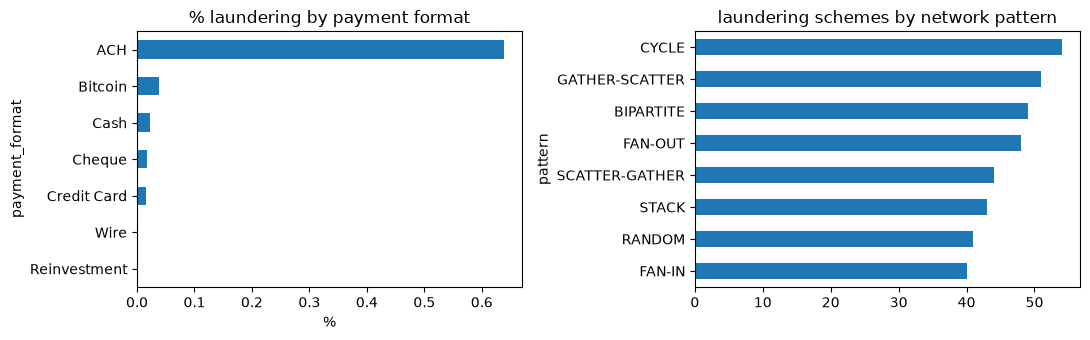

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
fmt = tx.groupby("payment_format").label.mean().sort_values()
(fmt * 100).plot.barh(ax=ax[0], title="% laundering by payment format"); ax[0].set_xlabel("%")
pat = D.laundering_patterns(RAW).groupby("pattern").attempt.nunique().sort_values()
pat.plot.barh(ax=ax[1], title="laundering schemes by network pattern"); plt.tight_layout()

Most laundering moves by ACH. The 8 network shapes (fan-in, fan-out, cycles, scatter-gather...) are what mule accounts do; ScamShield's receiver-side features look for them.